# Step 5: reliability (noise ceiling)

For each number that describes a trial (PC1 … PC10 of each task, start delay, movement duration): **is it a stable property of the session, or does it jump randomly from one repetition to the next?** A number that is not stable can never separate diseases, so this tells which numbers to keep for the next steps.

**Method:** split-half reliability, as the EEG noise ceiling of the NX-414 project (`compute_ceiling_splithalf`). There, "units" = the numbers here, "stimuli" = the units here (one session × one arm), "repetitions" = the trials.

Input: `pca_scores.parquet` and `shape_tables.parquet` (step 4: only the trials chosen there). Code: `reliability.py`.

In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd

import pca
import reliability

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

## Settings
Change a value, then re-run from here. They are saved next to the output (`reliability_settings.json`).

In [2]:
ARMS = "separate"            # "separate" = one unit per session and arm, "together" = one unit per session
N_PCS = 10                   # PCs tested per task (PC1..PC10)
EXTRA_MEASURES = ["start_delay_s", "movement_duration_s"]   # tested too
MIN_REPS = 4                 # a unit needs at least this many trials in a task (so each half has 2)
N_SPLITS = 100               # number of random splits averaged
SPEARMAN_BROWN = True        # correct for using only half of the trials in each half
CORRELATION = "pearson"      # "pearson" or "spearman"
RELIABLE_THRESHOLD = 0.7     # cells at or above this are marked as reliable in the plots
SEED = 0                     # for the random splits, so results can be reproduced

In [3]:
# The settings collected for the functions.
settings = {"arms": ARMS, "n_pcs": N_PCS, "extra_measures": EXTRA_MEASURES, "min_reps": MIN_REPS,
            "n_splits": N_SPLITS, "spearman_brown": SPEARMAN_BROWN, "correlation": CORRELATION,
            "reliable_threshold": RELIABLE_THRESHOLD, "seed": SEED}
measures = reliability.measure_names(N_PCS, EXTRA_MEASURES)

trials = reliability.load_trials()
step4 = reliability.step4_settings()
print(f"{len(trials)} trials, {trials['session_id'].nunique()} sessions")
print(f"PCA scores of step 4 made with SHAPE_PART = {step4['shape_part']!r}, points = {step4['points']}, "
      f"scale by arm length = {step4['scale_by_arm_length']}")
print(f"Numbers tested: {', '.join(measures)}")

2525 trials, 29 sessions
PCA scores of step 4 made with SHAPE_PART = 'whole', points = ['wrist'], scale by arm length = False
Numbers tested: PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10, start_delay_s, movement_duration_s


## 1. Units

A **unit** = one session × one arm (`ARMS = "separate"`) or one session (`ARMS = "together"`): the reliability asks whether the halves agree *across units*.

- The trials of each unit are split into two halves, so a unit needs at least `MIN_REPS` trials in a task (each half then has at least 2). Units with fewer are left out for that task.
- Tasks 4 and 6 (several targets): the split is done **within each target**, so both halves always contain the same targets. A target done only once by a unit cannot be split: it is left out for that unit (and not counted for `MIN_REPS`).
- `ARMS = "together"`: the split is also done within each arm, so both halves have the same mix of left and right trials.

In [4]:
trials = reliability.add_units(trials, ARMS)
units = reliability.units_table(trials, MIN_REPS)
print(f"Units kept: {units['kept'].sum()} of {len(units)} (task x unit)")
reliability.units_per_task(units)

Units kept: 165 of 174 (task x unit)


units       kept       left_out_by_min_reps      
arms                                            left right left right                 left right
task_id task_name                                                                               
1       Shoulder flexion with elbow extended      10    16   10    16                    0     0
2       Shoulder abduction with elbow extended     9    13    9    13                    0     0
3       Draw a 5 segment trajectory                8    12    7    10                    1     2
4       Reaching different targets                 7    11    7    10                    0     1
5       Draw a circle                              7    12    7    11                    0     1
6       Horizontal reaching                        8    19    8    15                    0     4
7       Drinking test: reaching glass to mouth    10    12   10    12                    0     0
8       Index to nose                              9    11    9    11                    0     0

## 2. Split-half reliability

In each of the `N_SPLITS` random splits, for each task and number:
1. split each unit's trials into two random halves of equal size (one trial left out at random if odd),
2. average half A and half B of every unit,
3. correlate half A with half B **across units** (`CORRELATION`),
4. Spearman-Brown correction r_sb = 2r / (1 + r): each half has only half of the trials, the corrected value is the reliability of the average of all of them.

Table: mean over the splits (`reliability`), 5th and 95th percentiles over the splits (how much it moves from one random split to another), units used, median trials per unit.

**How to read it:** 1 = the number is the same in both halves, a property of the session. 0 = random from one repetition to the next. Negative = not reliable (Spearman-Brown makes small negative correlations very negative: read any value ≤ 0 as 0).

**Chance level:** with about 20 units of about 11 trials (as here), pure noise gives at most about +0.45 by chance (99% of 300 simulated datasets). `RELIABLE_THRESHOLD = 0.7` is well above that.

In [5]:
table = reliability.split_half_reliability(trials, units, measures, settings)

with pd.option_context("display.max_rows", 120):
    display(table.round(3))

,task_id,task_name,measure,reliability,reliability_p05,reliability_p95,n_units,median_trials_per_unit
0,1,Shoulder flexion with elbow extended,PC1,0.979,0.967,0.988,26,11.0
1,1,Shoulder flexion with elbow extended,PC2,0.850,0.730,0.923,26,11.0
2,1,Shoulder flexion with elbow extended,PC3,0.907,0.828,0.953,26,11.0
3,1,Shoulder flexion with elbow extended,PC4,0.951,0.910,0.978,26,11.0
4,1,Shoulder flexion with elbow extended,PC5,0.986,0.972,0.994,26,11.0
5,1,Shoulder flexion with elbow extended,PC6,0.776,0.609,0.877,26,11.0
6,1,Shoulder flexion with elbow extended,PC7,0.825,0.729,0.908,26,11.0
7,1,Shoulder flexion with elbow extended,PC8,0.902,0.814,0.960,26,11.0
8,1,Shoulder flexion with elbow extended,PC9,0.797,0.660,0.889,26,11.0
9,1,Shoulder flexion with elbow extended,PC10,0.743,0.510,0.874,26,11.0


## 3. Heatmap
Rows = numbers, columns = tasks, value written in each cell. Framed = reliability ≥ `RELIABLE_THRESHOLD`. Colour: light = 0 (or below), dark = 1.

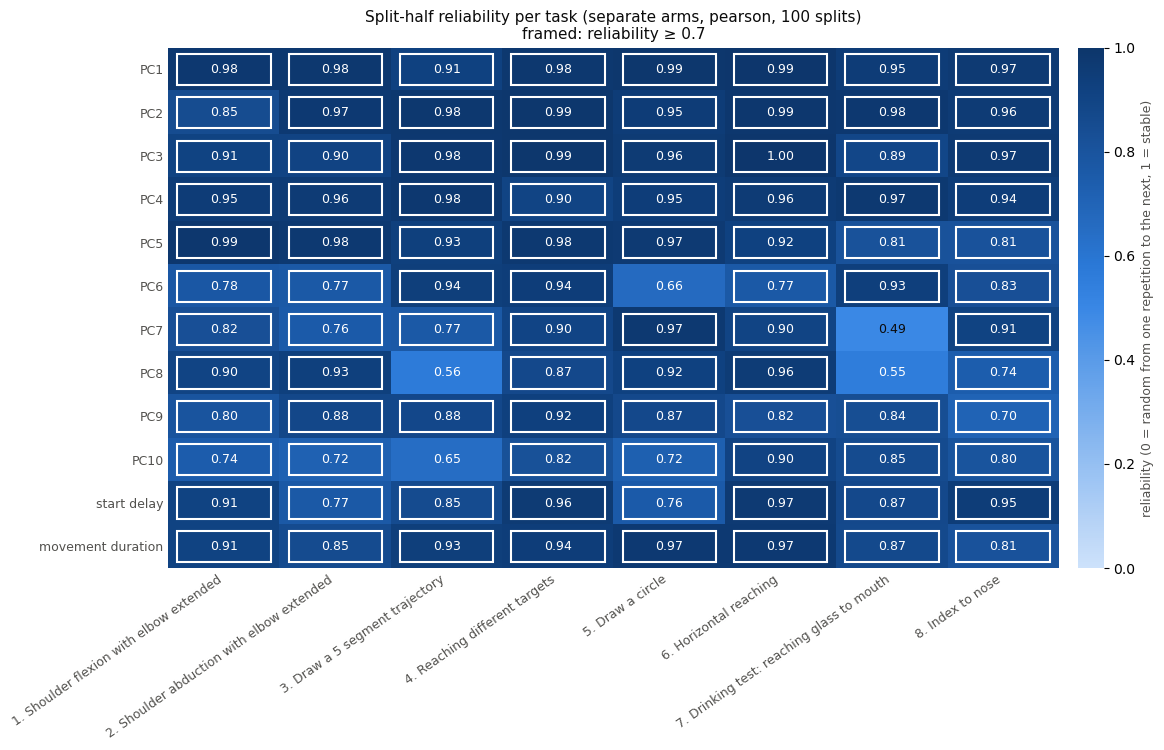

In [6]:
reliability.plot_heatmap(table, measures, RELIABLE_THRESHOLD,
                         f"Split-half reliability per task ({ARMS} arms, {CORRELATION}, {N_SPLITS} splits)")

## 4. Summary per task
How many PCs are at or above `RELIABLE_THRESHOLD`, which ones, and which other numbers.

⚠️ **Reliable does not mean meaningful.** Reliability only says that a number is the same from one repetition to the next *within a session*. Something that is constant within a session but has nothing to do with the person is reliable too: e.g. with `SHAPE_PART = "whole"`, PC1 of tasks 1 and 2 mostly says how the trials were ended (automatic before 02/09, by the operator after, see step 4), which is the same for every trial of a session, so it is very reliable. Reliability removes the numbers that are noise; it does not remove the artefacts.

In [7]:
reliability.reliable_summary(table, RELIABLE_THRESHOLD)

,task_name,n_reliable_PCs,reliable_PCs,reliable_other
task_id,,,,
1,Shoulder flexion with elbow extended,10,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"
2,Shoulder abduction with elbow extended,10,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"
3,Draw a 5 segment trajectory,8,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC9","start_delay_s, movement_duration_s"
4,Reaching different targets,10,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"
5,Draw a circle,9,"PC1, PC2, PC3, PC4, PC5, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"
6,Horizontal reaching,10,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"
7,Drinking test: reaching glass to mouth,8,"PC1, PC2, PC3, PC4, PC5, PC6, PC9, PC10","start_delay_s, movement_duration_s"
8,Index to nose,10,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10","start_delay_s, movement_duration_s"


## 5. The patients' two visits (just to look, no statistics)
For the persons who have both visit 1 and visit 2: the median of one number per visit, one panel per task, one line per person and arm (colour = condition, marker = person, as on the PCA maps). Choose the number in the cell.

⚠️ The visits come from `session_participant.csv`: JFR's first visit is **UNSURE** and all the manual assignments are to be confirmed by Luana.

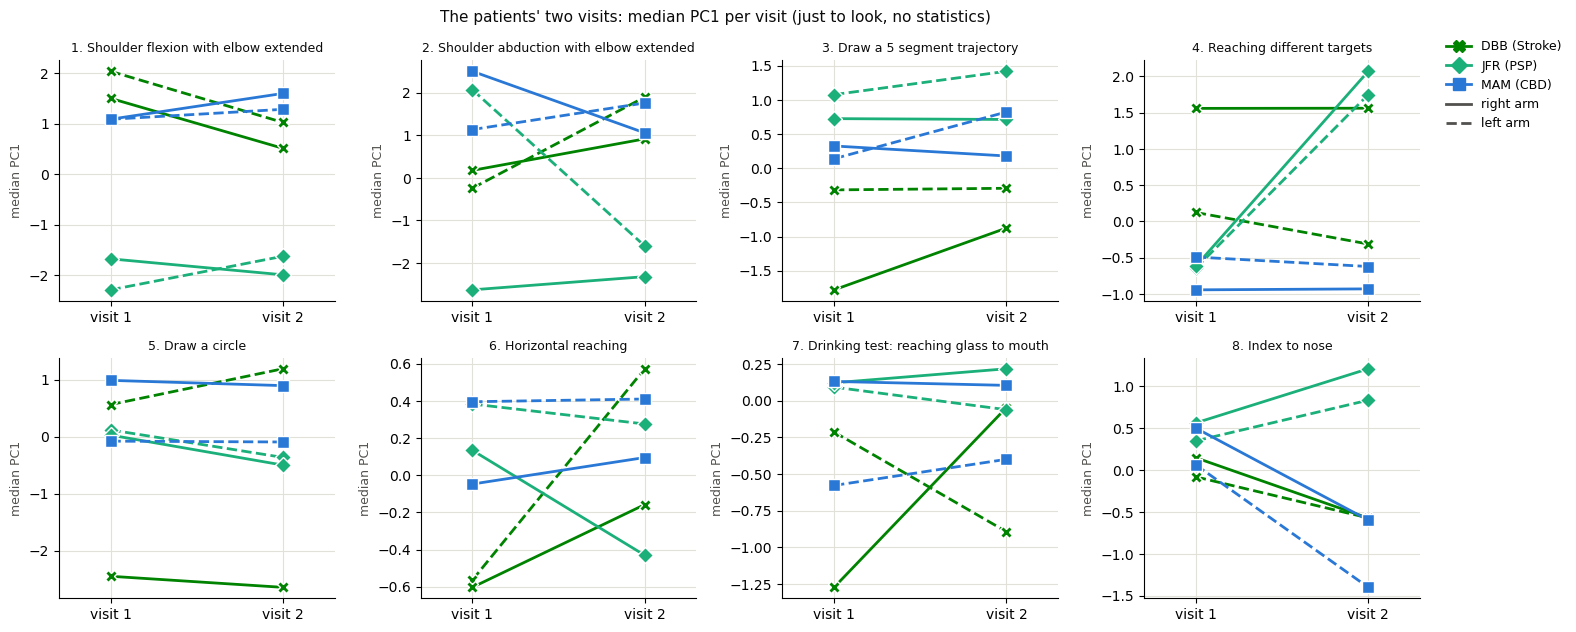

In [8]:
VISIT_MEASURE = "PC1"   # any of: PC1 ... PC10, start_delay_s, movement_duration_s

medians = reliability.visit_medians(trials, VISIT_MEASURE)
reliability.plot_visits(medians, VISIT_MEASURE, pca.plot_styles(trials))

## Save
Writes `reliability.parquet` (one row per task × number) and `reliability_settings.json` (the settings above) to `data/processed/`. Running it again overwrites them.

In [9]:
reliability.save_reliability(table, settings)

reliability.parquet             0.01 MB
reliability_settings.json       0.00 MB
